In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import pickle

from notebooks.imports import *

### Config

In [3]:
from config import dir_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

processed_dir = Path("/mnt/data/processed")

In [4]:
data = pd.read_csv(Path(processed_dir, "valid_data.csv"))

### Assemble and calibrate motion energy
Reads the shards written by `scripts/compute_motion_energy_full.py` (mouse-tuned, causal ME, 300 frames per trial), divides each rig and region by its ME-vs-coherence slope (units: equivalent % coherence) and writes:
- `motion_energies_normalized/me_{region}.pkl`: cut at the RT, NaN-padded to 600 frames (for kernels/analysis)
- `motion_energies_full/me_{region}.pkl`: not cut at the RT (for the DDM)
- `motion_energy_mouse/me_calibrated.npz`: all regions as arrays

This replaces the old `[:-3]` trim and per-session max normalization (see `dissemination/reports/motion-energy-methods.md`).

In [5]:
from scripts.assemble_motion_energy import main as assemble_motion_energy

assemble_motion_energy()

uw: slope 4.931 raw ME per % coherence, intercept -0.10 % coherence
ucla: slope 1.176 raw ME per % coherence, intercept +0.09 % coherence
data_source        ucla          uw
coherence                          
-100        -100.099998 -100.000000
-36          -35.500000  -36.200001
-18          -17.500000  -17.700001
-9            -8.800000   -9.300000
 0             0.100000   -0.600000
 9             8.900000    9.100000
 18           17.700001   17.500000
 36           35.700001   36.000000
 100         100.300003  100.000000
saved 25508 trials x 300 frames -> /mnt/data/processed/motion_energy_mouse/me_calibrated.npz
saved per-region pickles -> /mnt/data/processed/motion_energies_normalized (cut at RT), /mnt/data/processed/motion_energies_full (uncut)


### Sanity check: calibrated ME by coherence and rig (non-pulse trials)

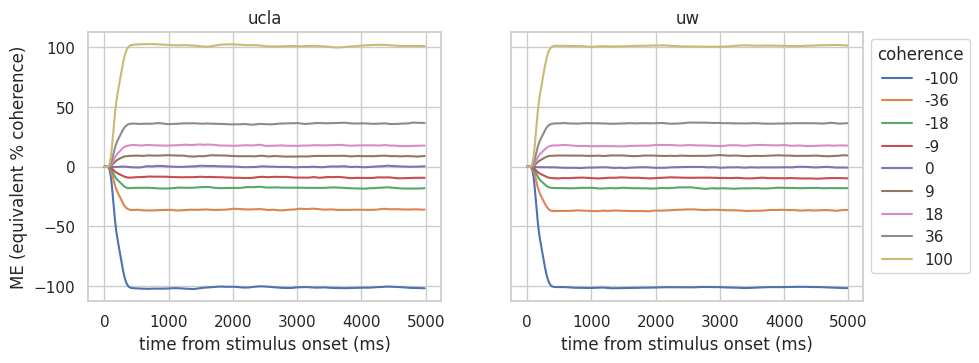

In [6]:
me = np.load(Path(processed_dir, "motion_energy_mouse/me_calibrated.npz"))
trials = data.set_index("agg_code").loc[me["agg_code"]]
non_pulse = ~trials.is_pulse_trial.to_numpy(bool)
t_ms = np.arange(me["n_frames"]) * 1000 / 60

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, rig in zip(axes, ["ucla", "uw"]):
    for coh in sorted(trials.signed_coherence.unique()):
        rows = non_pulse & (trials.data_source == rig).to_numpy() & (trials.signed_coherence == coh).to_numpy()
        ax.plot(t_ms, me["global"][rows].mean(axis=0), label=coh)
    ax.set(title=rig, xlabel="time from stimulus onset (ms)")
axes[0].set_ylabel("ME (equivalent % coherence)")
axes[1].legend(title="coherence", bbox_to_anchor=(1, 1))